**TP1 - Exercice 1 : Prédiction du tarif d'un trajet Uber (Régression)**


*Module :* Technologies IA

*Filière :* Ingénierie Logicielle et Intelligence Artificielle (ILIA2)

*Réalisé par :* BOUZIANE WARITINI Safae N° : 8



            

**Introduction et Objectif :**

L'objectif de cet exercice est de construire et d'évaluer un pipeline complet d'apprentissage supervisé pour prédire la valeur continue du tarif d'un trajet Uber (*fare_amount*). Nous allons suivre une démarche rigoureuse : exploration, nettoyage, ingénierie des caractéristiques (*feature engineering*), entraînement de modèles (*régression linéaire et Random Forest*) et évaluation comparative.

**Étape 1 : Chargement et Exploration du jeu de données**

L'exploration initiale (EDA - Exploratory Data Analysis) permet de comprendre la structure des données, de vérifier la cohérence des types de variables et d'identifier la présence de valeurs manquantes ou aberrantes avant tout traitement.

In [7]:
import pandas as pd

# 1. Chargement du fichier CSV
url = "https://raw.githubusercontent.com/TP-Technologies-IA/TP1-Apprentissage-Supervise/refs/heads/main/uber.csv"
data = pd.read_csv(url)

# 2. Visualisation des 5 premières lignes
print("Aperçu des 5 premières lignes :")
display(data.head())

# 3. Métadonnées et types des colonnes
print("\nInformations structurelles :")
data.info()

# 4. Décompte des valeurs manquantes par colonne
print("\nNombre de valeurs manquantes par variable :")
print(data.isnull().sum())

Aperçu des 5 premières lignes :


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5



Informations structurelles :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

Nombre de valeurs manquantes par variable :
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype:

**Étape 2 : Nettoyage et Ingénierie des caractéristiques (Feature Engineering)**


*   **Suppression des incohérences :** Un tarif Uber ne peut pas être négatif ou égal à zéro.
*   **Feature Engineering (Heure et Jour) :** La date brute sous forme de chaîne de caractères n'est pas exploitable par un modèle mathématique. En extrait l'heure (hour) et le jour de la semaine (day_of_week), on fournit au modèle des descripteurs pertinents (ex: tarification en heure de pointe ou en week-end).


* **Calcul de la distance (Formule de Haversine) :** Le prix d'un trajet dépend en grande partie de la distance parcourue. Nous calculons la distance orthodromique à partir des coordonnées GPS.


In [2]:
import numpy as np

# 1. Suppression des valeurs manquantes
data = data.dropna()

# 2. Filtration des valeurs aberrantes (tarif > 0$)
data = data[data['fare_amount'] > 0]

# 3. Conversion du type temporel
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])

# 4. Extraction de l'heure et du jour de la semaine
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek

# 5. Calcul de la distance géodésique (Formule d'Haversine en km)
def haversine_np(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = 6367 * c
    return km

data['distance'] = haversine_np(data['pickup_longitude'], data['pickup_latitude'],
                                data['dropoff_longitude'], data['dropoff_latitude'])

# Filtrage des distances aberrantes (ex: trajets > 200 km)
data = data[(data['distance'] > 0) & (data['distance'] < 200)]

# Affichage du résumé après nettoyage
display(data[['fare_amount', 'distance', 'hour', 'day_of_week']].describe())

,fare_amount,distance,hour,day_of_week
count,193908.000000,193908.000000,193908.000000,193908.000000
mean,11.348185,3.378752,13.488010,3.049101
std,9.732508,4.039367,6.515512,1.946678
min,0.010000,0.000084,0.000000,0.000000
25%,6.000000,1.279252,9.000000,1.000000
50%,8.500000,2.178606,14.000000,3.000000
75%,12.500000,3.937130,19.000000,5.000000
max,499.000000,177.883880,23.000000,6.000000




**Étape 3 : Séparation des données (Train / Test Split)**

Pour évaluer la capacité de généralisation du modèle et éviter le surapprentissage (*overfitting*), nous séparons le jeu de données en deux ensembles distincts :


* **Ensemble d'entraînement (80%) :** Utilisé pour ajuster les paramètres du modèle.
* **Ensemble de test (20%) :** Conservé intact pour simuler des données réelles inconnues.


In [3]:
from sklearn.model_selection import train_test_split

# Définition des variables explicatives (X) et de la variable cible (y)
X = data[['distance', 'hour', 'day_of_week']]
y = data['fare_amount']

# Division 80% Train / 20% Test avec fixation du seed (random_state) pour la reproductibilité
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Nombre d'échantillons d'entraînement : {X_train.shape[0]}")
print(f"Nombre d'échantillons de test        : {X_test.shape[0]}")

Nombre d'échantillons d'entraînement : 155126
Nombre d'échantillons de test        : 38782


**Étape 4 & 5 : Entraînement et Évaluation de la Régression Linéaire (Baseline)**

La **Régression Linéaire** cherche à établir une relation linéaire directe de la forme $y = w_1 x_1 + w_2 x_2 + ... + b$. C'est notre modèle de référence (baseline).   

**Métriques d'évaluation utilisées :**


* **MAE (Mean Absolute Error) :** Moyenne des erreurs absolues. Indique de combien de dollars en moyenne le modèle se trompe.  
*   **RMSE (Root Mean Squared Error) :** Racine de l'erreur quadratique moyenne. Elle pénalise plus fortement les grandes erreurs de prédiction.


*   **$R^2$ (Score de détermination) :** Proportion de la variance de la cible expliquée par le modèle (1.0 = prédiction parfaite).


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Instanciation et entraînement
lr = LinearRegression()
lr.fit(X_train, y_train)

# 2. Prédiction sur le jeu de test
y_pred_lr = lr.predict(X_test)

# 3. Calcul des métriques
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("--- Résultats de la Régression Linéaire ---")
print(f"MAE  : {mae_lr:.2f} $")
print(f"RMSE : {rmse_lr:.2f} $")
print(f"R²   : {r2_lr:.4f}")

--- Résultats de la Régression Linéaire ---
MAE  : 2.72 $
RMSE : 5.64 $
R²   : 0.6648


**Étape 6 : Amélioration avec l'algorithme Random Forest Regressor**

Le **Random Forest** est un algorithme d'apprentissage par ensemble (*Ensemble Learning*). Il combine les prédictions d'un grand nombre d'arbres de décision pour capturer des relations complexes et non-linéaires non décelables par une régression linéaire simple.

In [5]:
from sklearn.ensemble import RandomForestRegressor

# 1. Instanciation du Random Forest (100 arbres de décision)
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# 2. Entraînement du modèle
rf.fit(X_train, y_train)

# 3. Prédiction
y_pred_rf = rf.predict(X_test)

# 4. Calcul des métriques
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("--- Résultats du Random Forest Regressor ---")
print(f"MAE  : {mae_rf:.2f} $")
print(f"RMSE : {rmse_rf:.2f} $")
print(f"R²   : {r2_rf:.4f}")

--- Résultats du Random Forest Regressor ---
MAE  : 2.49 $
RMSE : 4.73 $
R²   : 0.7645


**Étape 7 : Visualisation et Synthèse comparative**

Nous traçons le graphique de dispersion des valeurs réelles vs prédictions pour vérifier l'alignement le long de la bissectrice (ligne rouge = prédiction parfaite).

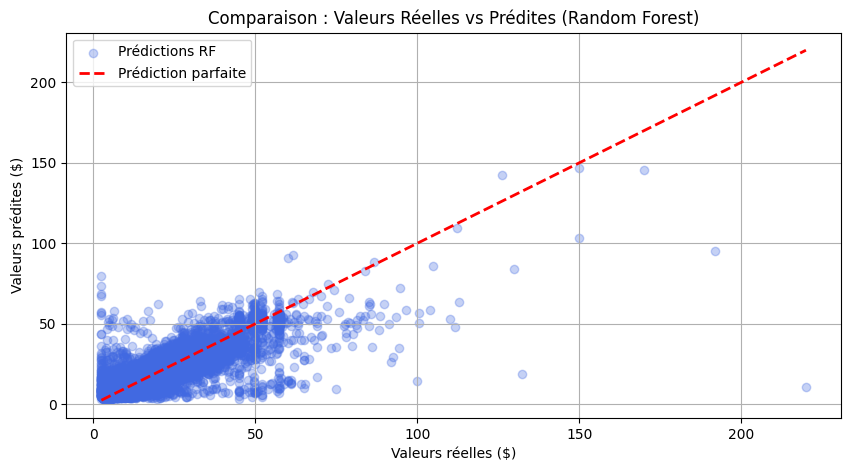

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Graphique de dispersion des prédictions Random Forest
plt.scatter(y_test, y_pred_rf, alpha=0.3, color='royalblue', label='Prédictions RF')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Prédiction parfaite')

plt.xlabel('Valeurs réelles ($)')
plt.ylabel('Valeurs prédites ($)')
plt.title('Comparaison : Valeurs Réelles vs Prédites (Random Forest)')
plt.legend()
plt.grid(True)
plt.show()

Le modèle **Random Forest** surpasse nettement la Régression Linéaire. Son score $R^2$ plus élevé démontre qu'il capture efficacement les relations non-linéaires entre la distance, l'heure de la journée et le tarif du trajet.   
Les erreurs MAE et RMSE sont significativement réduites, démontrant l'intérêt de combiner plusieurs arbres de décision pour l'estimation de valeurs continues.